In [2]:
import numpy as np
import pandas as pd

In [3]:
#from sklearn.datasets import fetch_openml
#mnist = fetch_openml(data_id=554, as_frame=False) --> dataframe olmasin diye as_frame=False yaziriq

In [4]:
from sklearn.datasets import fetch_openml
#Try fetching the dataset using its dataID instead of the name
mnist = fetch_openml(data_id=554, as_frame=False)
#data_id=554 corresponds to the MNIST dataset on OpenML

In [5]:
print(mnist.DESCR)

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

In [6]:
X=mnist['data']
y=mnist['target']

In [7]:
X[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 17

In [8]:
X[0].shape

(784,)

In [9]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [10]:
X.shape

(70000, 784)

In [11]:
print(X[1].reshape(28,28))

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  51 159 253
  159  50   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0  48 238 252 252
  252 237   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  54 227 253 252 239
  233 252  57   6   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  10  60 224 252 253 252 202
   84 252 253 122   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0 163 252 252 252 25

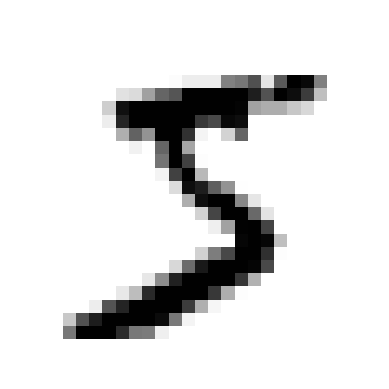

In [12]:
import matplotlib.pyplot as plt
def digit_image(num_image):
  num_image_reshaped = num_image.reshape(28,28)
  plt.imshow(num_image_reshaped, cmap='binary')
  plt.axis('off')

some_digit = X[0]
digit_image(some_digit)

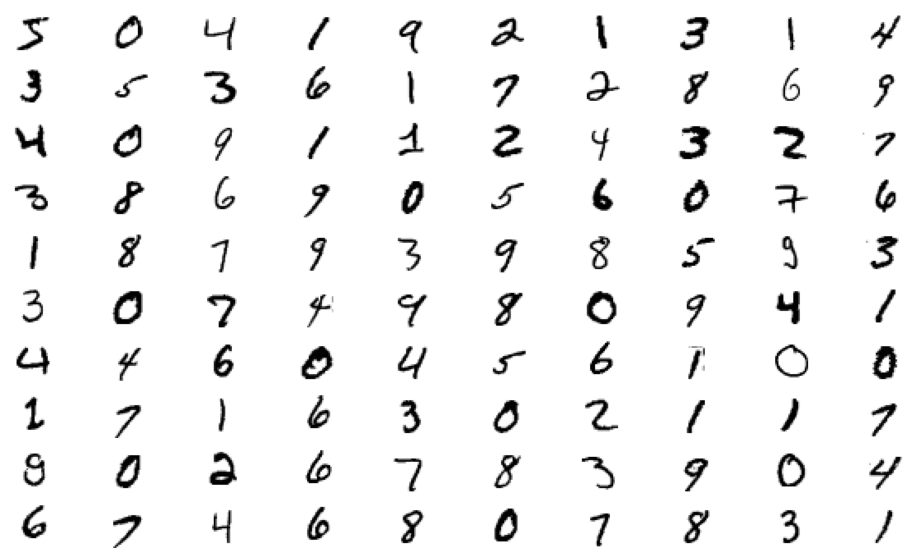

In [13]:
plt.figure(figsize=(12,7))
for idx, image in enumerate(X[:100]):
  plt.subplot(10,10,idx+1)
  digit_image(image)

In [14]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [15]:
y_train

array(['5', '0', '4', ..., '5', '6', '8'], dtype=object)

In [16]:
y_train == '5'

array([ True, False, False, ...,  True, False, False])

In [17]:
y_train_5 = (y_train == '5')
y_test_5 = (y_test == '5')

In [18]:
X_train[y_train_5][1]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   

In [19]:
#binered classification multiclass classification multilabel classification multioutput classification

In [20]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score


In [21]:
sgd_clf = SGDClassifier(random_state=42)

In [22]:
sgd_clf.fit(X_train, y_train_5)

SGDClassifier(random_state=42)

In [23]:
t=[0.95035, 0.96035, 0.9604]
np.mean(t)

np.float64(0.9570333333333334)

In [24]:
sgd_clf.predict([some_digit])

array([ True])

In [25]:
sgd_clf.score(X_test,y_test_5)

0.9492

In [26]:
1-(sum(y_train=='5')/len(y_train))

np.float64(0.90965)

In [27]:
from sklearn.dummy import DummyClassifier

dummy_clf=DummyClassifier()
dummy_clf.fit(X_train,y_train_5)
print(any(dummy_clf.predict(X_test)))

False


In [28]:
dummy_clf.score(X_train,y_train_5)

0.90965

In [29]:
from sklearn.model_selection import cross_val_score
preds=cross_val_score(sgd_clf,X_train,y_train_5,cv=3)
preds

array([0.95035, 0.96035, 0.9604 ])

In [30]:
from sklearn.model_selection import cross_val_predict

preds = cross_val_predict(sgd_clf, X_train, y_train_5, cv = 3)
preds

array([ True, False, False, ...,  True, False, False])

In [31]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_train_5, preds)
cm

array([[53892,   687],
       [ 1891,  3530]])

In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [33]:
precision_score(y_train_5, preds) * 10

8.370879772350012

In [34]:
recall_score(y_train_5, preds) * 100

65.11713705958311

In [35]:
f1_score(y_train_5, preds) * 100

73.25171197343847

In [36]:
y_scores= sgd_clf.decision_function([some_digit])
y_scores

array([2164.22030239])

In [37]:
treshold = 0
y_some_digit_pred=(y_scores>treshold)
y_some_digit_pred

array([ True])

In [38]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method='decision_function')
y_scores

array([  1200.93051237, -26883.79202424, -33072.03475406, ...,
        13272.12718981,  -7258.47203373, -16877.50840447])

In [39]:
y_train_5

array([ True, False, False, ...,  True, False, False])

In [40]:
sum((y_scores>5)==y_train_5)/len(y_train_5)

np.float64(0.9570166666666666)

In [41]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, tresholds = precision_recall_curve(y_train_5, y_scores)

In [42]:
tresholds

array([-146348.56726174, -142300.00705404, -137588.97581744, ...,
         38871.26391927,   42216.05562787,   49441.43765905])

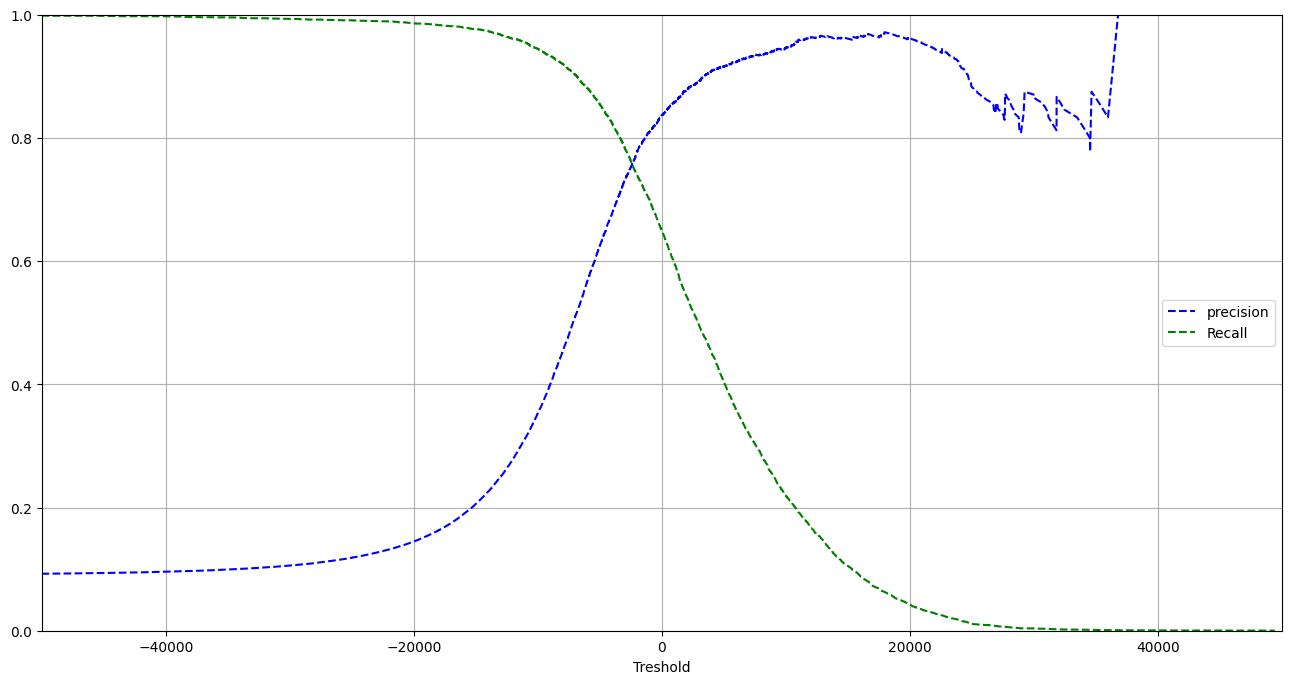

In [43]:
plt.figure(figsize=(16,8))
plt.plot(tresholds,precisions[:-1],'b--',label="precision")
plt.plot(tresholds,recalls[:-1],'g--',label="Recall")

plt.axis([-50000,50000,0,1])
plt.grid()
plt.xlabel('Treshold')
plt.legend(loc='center right')

In [44]:
idx_for_90_precision = (precisions>0.9).argmax()
treshold_for_90_precision = tresholds[idx_for_90_precision]
treshold_for_90_precision

np.float64(3370.0194991439557)

In [45]:
idx_for_equal_precision=(precisions==recalls).argmax()
treshold_for_equal_precision = tresholds[idx_for_equal_precision]
treshold_for_equal_precision

np.float64(-2379.064500932274)

In [46]:
y_train_pred_90 = (y_scores>treshold_for_90_precision)
y_train_pred_90

array([False, False, False, ...,  True, False, False])

In [47]:
precision_score(y_train_5, y_train_pred_90)

0.9

In [48]:
recall_at_90_precision=recall_score(y_train_5,y_train_pred_90)
recall_at_90_precision

0.47980077476480354

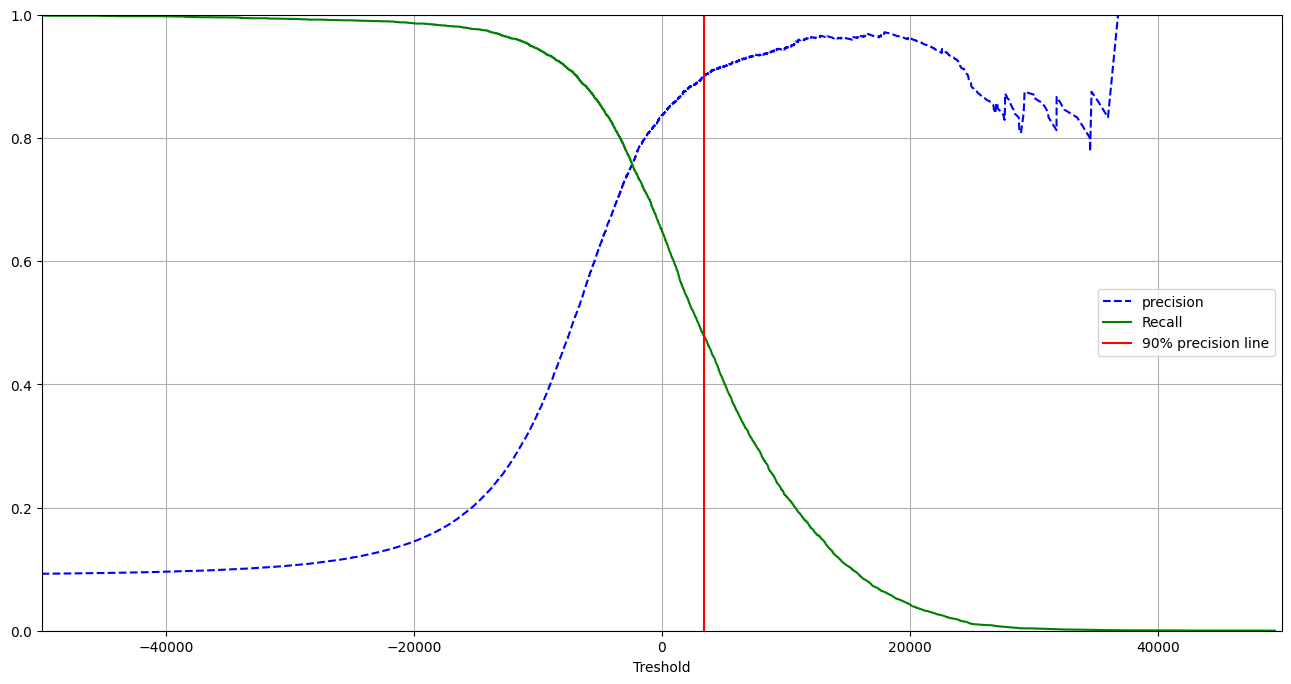

In [49]:
plt.figure(figsize = (16, 8))
plt.plot(tresholds, precisions[:-1], 'b--', label = "precision")
plt.plot(tresholds, recalls[:-1], 'g-', label = 'Recall')

plt.axis([-50000, 50000, 0, 1])
plt.grid()
plt.xlabel('Treshold')
plt.axvline(x = treshold_for_90_precision, ymin=0, ymax=1, color = 'r', label = '90% precision line')
plt.legend(loc = 'center right');

In [50]:
from sklearn.metrics import roc_curve
fpr,tpr,tresholds = roc_curve(y_train_5,y_scores)

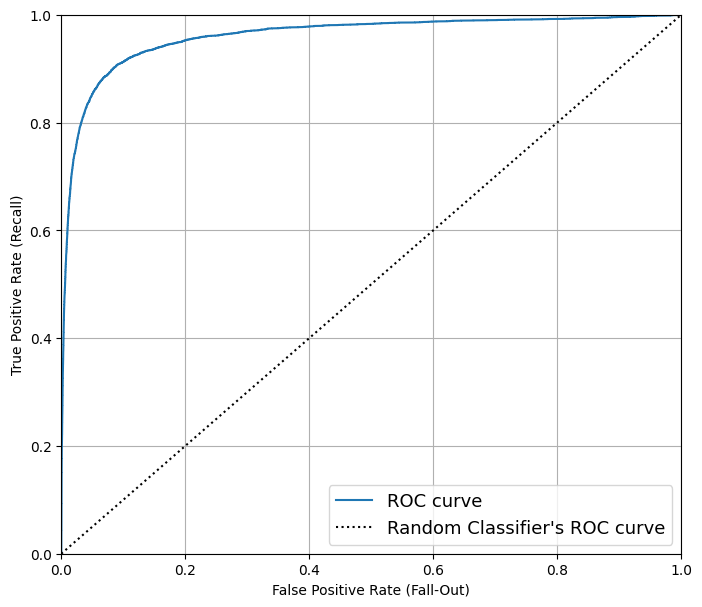

In [51]:
plt.figure(figsize=(8,7))
plt.plot(fpr,tpr,label='ROC curve')
plt.plot([0,1],[0,1],'k:',label="Random Classifier's ROC curve")
plt.xlabel('False Positive Rate (Fall-Out)')
plt.ylabel('True Positive Rate (Recall)')
plt.grid()
plt.axis([0,1,0,1])
plt.legend(loc='lower right',fontsize=13)

In [52]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_5,y_scores)

np.float64(0.9604938554008616)

In [53]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)

In [54]:
y_probas_forest = cross_val_predict(forest_clf,
                                    X_train,
                                    y_train_5,
                                    cv=3,
                                    method='predict_proba')

In [55]:
y_probas_forest[:2]

array([[0.11, 0.89],
       [0.99, 0.01]])

In [56]:
y_scores_forest = y_probas_forest[:,1]
precisions_forest, recalls_forest, tresholds_forest = precision_recall_curve(
    y_train_5, y_scores_forest)

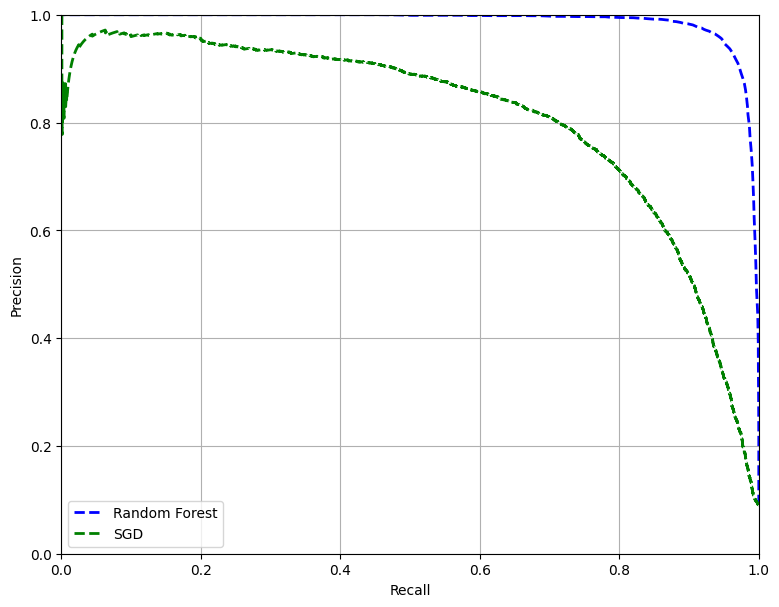

In [57]:
plt.figure(figsize = (9,7))

plt.plot(recalls_forest,precisions_forest,'b--',linewidth=2,label='Random Forest')
plt.plot(recalls,precisions,'g--',linewidth=2,label='SGD')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.axis([0,1,0,1])
plt.grid()
plt.legend(loc='lower left')

In [58]:
y_train_pred_forest=y_probas_forest[:,1]>=0.5
f1_score(y_train_5,y_train_pred_forest)

0.9274509803921569

In [59]:
roc_auc_score(y_train_5,y_scores_forest)

np.float64(0.9983436731328145)

In [60]:
recall_score(y_train_5,y_train_pred_forest)

0.8725327430363402

In [61]:
#Multiclass Classification




In [62]:
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])


SVC(random_state=42)

In [63]:
svm_clf.predict([some_digit])

array(['5'], dtype=object)

In [64]:
some_digit_scores= svm_clf.decision_function([some_digit])
some_digit_scores.round(2)

array([[ 3.79,  0.73,  6.06,  8.3 , -0.29,  9.3 ,  1.75,  2.77,  7.21,
         4.82]])

In [65]:
class_id = some_digit_scores.argmax()
class_id

np.int64(5)

In [66]:
svm_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [67]:
svm_clf.classes_[class_id]

'5'

In [68]:
svm_clf.decision_function_shape='ovo'
some_digit_scores_ovo=svm_clf.decision_function([some_digit])
some_digit_scores_ovo.round(2)

array([[ 0.11, -0.21, -0.97,  0.51, -1.01,  0.19,  0.09, -0.31, -0.04,
        -0.45, -1.28,  0.25, -1.01, -0.13, -0.32, -0.9 , -0.36, -0.93,
         0.79, -1.  ,  0.45,  0.24, -0.24,  0.25,  1.54, -0.77,  1.11,
         1.13,  1.04,  1.2 , -1.42, -0.53, -0.45, -0.99, -0.95,  1.21,
         1.  ,  1.  ,  1.08, -0.02, -0.67, -0.14, -0.3 , -0.13,  0.25]])

In [69]:
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])

SVC(random_state=42)

In [70]:
from sklearn.multiclass import OneVsRestClassifier
ovr_clf = OneVsRestClassifier(SVC(random_state=42))
ovr_clf.fit(X_train[:2000], y_train[:2000])

OneVsRestClassifier(estimator=SVC(random_state=42))

In [71]:
ovr_clf.predict([some_digit])

array(['5'], dtype='<U1')

In [72]:
sgd_clf.decision_function([some_digit]).round()

array([2164.])

In [73]:
cross_val_score(sgd_clf,X_train,y_train,cv=3,scoring='accuracy')

array([0.87365, 0.85835, 0.8689 ])

In [74]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train.astype('float64'))
cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring = 'accuracy')

array([0.8983, 0.891 , 0.9018])

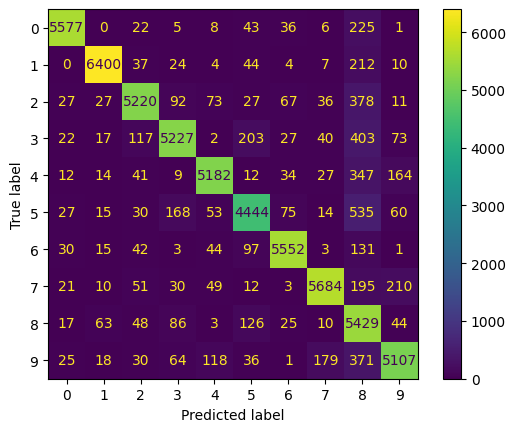

In [75]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
plt.show()


In [76]:
#MULTILABEL CLASSIFICATION

In [77]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train.astype('int8') >= 7)
y_train_odd = (y_train.astype('int8') % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)

KNeighborsClassifier()

In [78]:
pd.DataFrame(y_multilabel,columns=['is_greater_than_seven?','is_odd'])

,is_greater_than_seven?,is_odd
0,False,True
1,False,False
2,False,False
3,False,True
4,True,True
...,...,...
59995,True,False
59996,False,True
59997,False,True
59998,False,False


In [79]:
knn_clf.predict(X_train[:3])

array([[False,  True],
       [False, False],
       [False, False]])

In [80]:
y_train

array(['5', '0', '4', ..., '5', '6', '8'], dtype=object)

In [81]:
y_train_knn_pred=cross_val_predict(knn_clf,X_train,y_multilabel,cv=3)
f1_score(y_multilabel,y_train_knn_pred,average='macro')

In [82]:
import random
np.random.seed(42)
noise = np.random.randint(0, 100, (len(X_train), 784))
X_train_mod = X_train + noisnoise = np.random.randint(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise
y_train_mod = X_train
y_test_mod = X_test

In [83]:
X[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 17

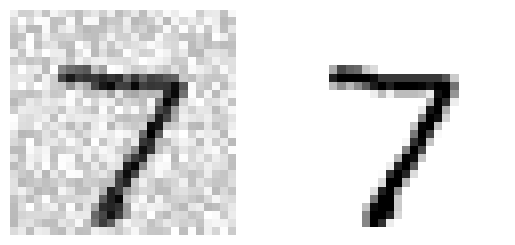

In [92]:
plt.subplot(121);
digit_image(X_test_mod[0])
plt.subplot(122);
digit_image(y_test_mod[0])
plt.show()

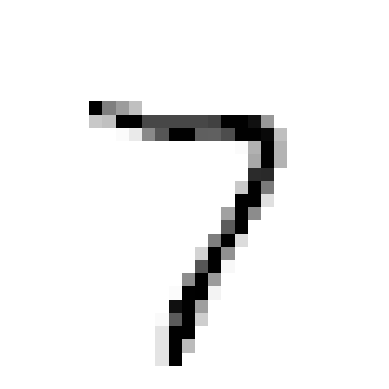

In [93]:
knn_clf=KNeighborsClassifier()
knn_clf.fit(X_train_mod,y_train_mod)
cleaned_pic=knn_clf.predict([X_test_mod[0]])
digit_image(cleaned_pic)

In [94]:
knn_clf=KNeighborsClassifier()
knn_clf.fit(X_train,y_train)
baseline_accuracy = knn_clf.score(X_test,y_test)
baseline_accuracy

0.9688

In [ ]:
#TASK


In [95]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

param_grid = [
    {'n_neighbors': [3, 4, 5],
     'weights': ['uniform', 'distance']
     }]

knn_clf = KNeighborsClassifier()
grid_search = GridSearchCV(knn_clf, param_grid, cv=3)
grid_search.fit(X_train[:10000], y_train[:10000])

GridSearchCV(cv=3, estimator=KNeighborsClassifier(),
             param_grid=[{'n_neighbors': [3, 4, 5],
                          'weights': ['uniform', 'distance']}])

In [96]:
grid_search.best_params_

{'n_neighbors': 4, 'weights': 'distance'}

In [97]:
grid_search.best_score_

np.float64(0.9397994088551026)

In [90]:
grid_search.best_estimator_

KNeighborsClassifier(n_neighbors=4, weights='distance')

In [98]:
grid_search.best_estimator_.fit(X_train,y_train)
turned_accuracy = grid_search.score(X_test,y_test)
turned_accuracy

0.9714